# Pew's World Religion Projections 2010 to 2050 Dataset


In [3]:
import numpy as ny
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data loading and inspection

In [4]:
df = pd.read_csv('rounded_population (1).csv', skipinitialspace=True)

df.dtypes
df.info()
df.shape
df.describe()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 1205 entries, 0 to 1204
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Year             1205 non-null   int64
 1   Region           1205 non-null   str  
 2   Country          1205 non-null   str  
 3   Christians       1205 non-null   int64
 4   Muslims          1205 non-null   int64
 5   Unaffiliated     1205 non-null   int64
 6   Hindus           1205 non-null   int64
 7   Buddhists        1205 non-null   int64
 8   Folk Religions   1205 non-null   int64
 9   Other Religions  1205 non-null   int64
 10  Jews             1205 non-null   int64
 11  All Religions    1205 non-null   int64
dtypes: int64(10), str(2)
memory usage: 113.1 KB


,Year,Region,Country,Christians,Muslims,Unaffiliated,Hindus,Buddhists,Folk Religions,Other Religions,Jews,All Religions
0,2010,World,All Countries,2168330000,1599700000,1131150000,1032210000,487760000,404690000,58150000,13860000,6895850000
1,2010,North America,All Countries,266630000,3480000,59040000,2250000,3860000,1020000,2200000,6040000,344530000
2,2010,Latin America-Caribbean,All Countries,531280000,840000,45390000,660000,410000,10040000,990000,470000,590080000
3,2010,Europe,All Countries,553280000,43470000,139890000,1380000,1350000,870000,890000,1420000,742550000
4,2010,Middle East-North Africa,All Countries,12710000,317070000,2100000,1720000,500000,1060000,230000,5630000,341020000


## Data cleaning

In [5]:
# none found
df.isnull().sum()
df.duplicated().sum()

# the columns were not matching because of the extra spaces
df["Region"] = df["Region"].str.strip()
df["Country"] = df["Country"].str.strip()

## Feature Engineering

In [6]:
df['Major_Religions_Population'] = df[['Christians', 'Muslims', 'Hindus', 'Buddhists']].sum(axis=1)

religions = ['Christians', 'Muslims', 'Hindus', 'Buddhists', 'Jews', 'Folk Religions', 'Other Religions']
df['Religious Total'] = df[religions].sum(axis=1)
df['Atheists/Agnostics %'] = df['Unaffiliated'] / df['All Religions'] * 100

df.head()

,Year,Region,Country,Christians,Muslims,Unaffiliated,Hindus,Buddhists,Folk Religions,Other Religions,Jews,All Religions,Major_Religions_Population,Religious Total,Atheists/Agnostics %
0,2010,World,All Countries,2168330000,1599700000,1131150000,1032210000,487760000,404690000,58150000,13860000,6895850000,5288000000,5764700000,16.403344
1,2010,North America,All Countries,266630000,3480000,59040000,2250000,3860000,1020000,2200000,6040000,344530000,276220000,285480000,17.136389
2,2010,Latin America-Caribbean,All Countries,531280000,840000,45390000,660000,410000,10040000,990000,470000,590080000,533190000,544690000,7.692177
3,2010,Europe,All Countries,553280000,43470000,139890000,1380000,1350000,870000,890000,1420000,742550000,599480000,602660000,18.839135
4,2010,Middle East-North Africa,All Countries,12710000,317070000,2100000,1720000,500000,1060000,230000,5630000,341020000,332000000,338920000,0.615800


## Univariate Analysis

### Histogram (Muslim Population)

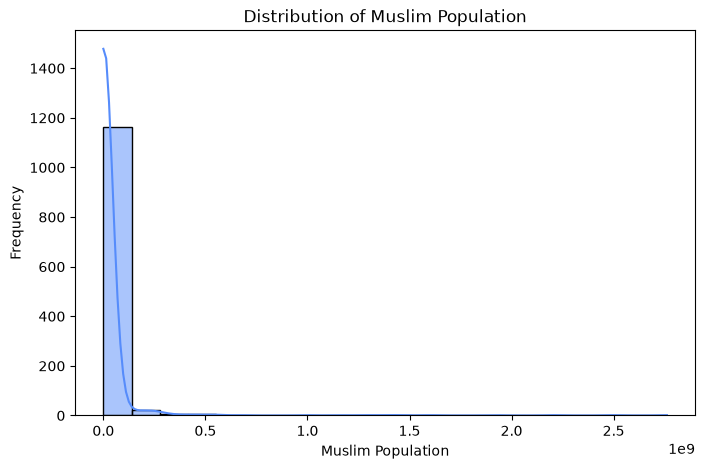

In [22]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x='Muslims', bins=20, kde=True)

plt.title('Distribution of Muslim Population')
plt.xlabel('Muslim Population')
plt.ylabel('Frequency')

plt.show()


### Bar Graph (Major Religions Population)


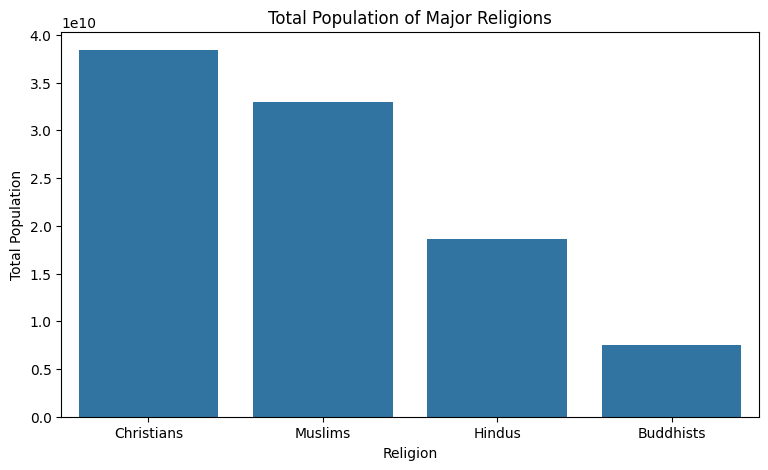

In [6]:
religions = ['Christians', 'Muslims', 'Hindus', 'Buddhists']

religion_totals = df[religions].sum()

plt.figure(figsize=(9,5))

sns.barplot(
    x=religion_totals.index,
    y=religion_totals.values
)

plt.title('Total Population of Major Religions')
plt.xlabel('Religion')
plt.ylabel('Total Population')

plt.show()


### Countplot (Regional distribution)

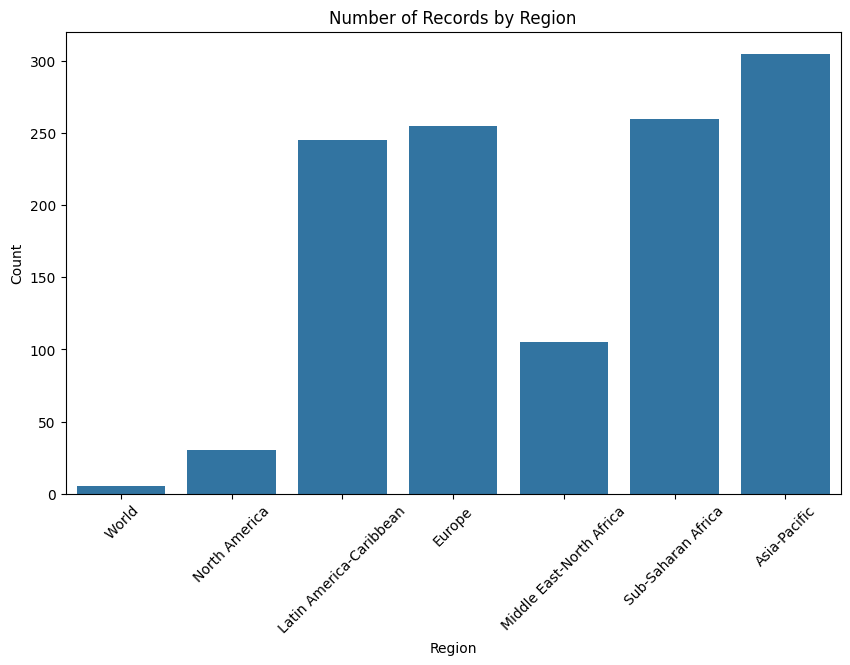

In [7]:
plt.figure(figsize=(10,6))

sns.countplot(data=df, x='Region')

plt.title('Number of Records by Region')
plt.xlabel('Region')
plt.ylabel('Count')

plt.xticks(rotation=45)

plt.show()

### Boxplot (Population Outliers)

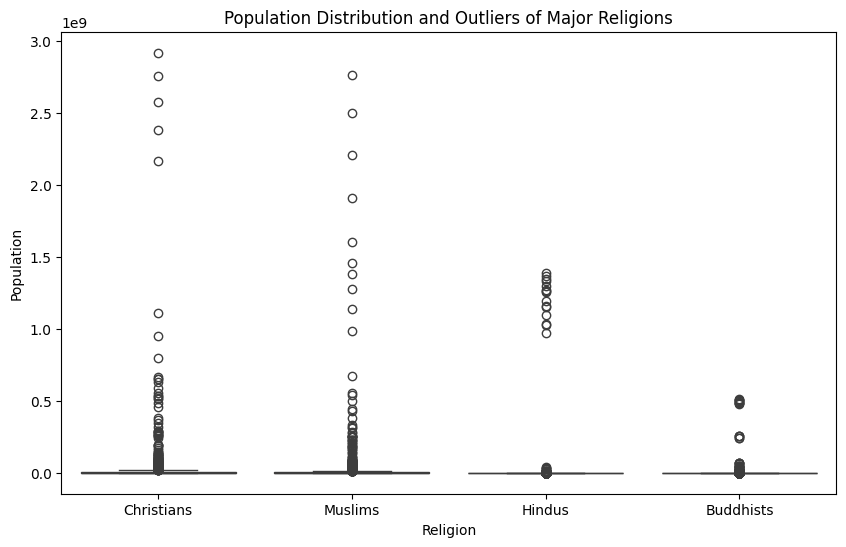

In [8]:
religions = ['Christians', 'Muslims', 'Hindus', 'Buddhists']

plt.figure(figsize=(10,6))

sns.boxplot(data=df[religions])

plt.title('Population Distribution and Outliers of Major Religions')
plt.xlabel('Religion')
plt.ylabel('Population')

plt.show()

## Bivariate Analysis

### Scatter plot (Muslims vs Christians)

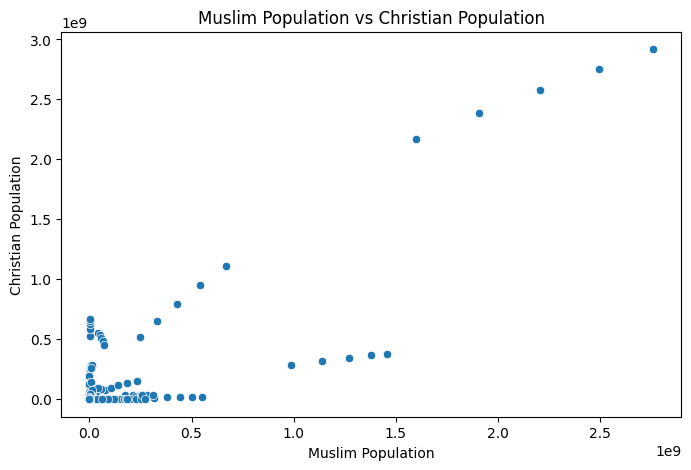

In [9]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x='Muslims', y='Christians')

plt.title('Muslim Population vs Christian Population')
plt.xlabel('Muslim Population')
plt.ylabel('Christian Population')

plt.show()

### Boxplot (Region vs Muslim Population)

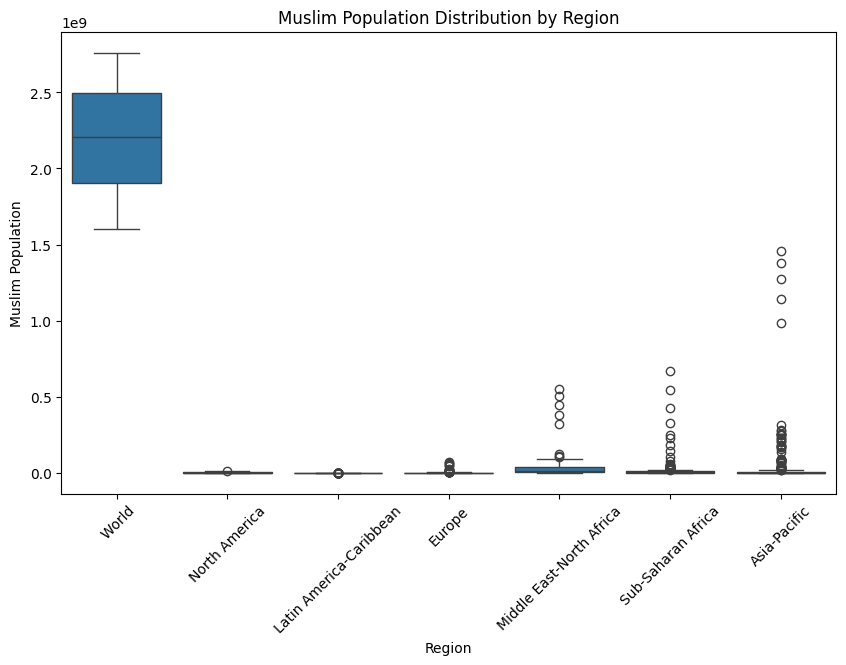

In [10]:
plt.figure(figsize=(10,6))

sns.boxplot(data=df, x='Region', y='Muslims')

plt.title('Muslim Population Distribution by Region')
plt.xlabel('Region')
plt.ylabel('Muslim Population')

plt.xticks(rotation=45)

plt.show()

## Heatmaps (Religious composition shifts, 2010 to 2050)

Red = share falls, blue = share rises (percentage points). Blank cells = group too small to measure.


In [10]:
religions = list(df.columns[3:-1])  # the 8 religion columns


def share_change(data, key):
    """Share in 2050 minus share in 2010, in percentage points."""
    a = data[data.Year == 2010].set_index(key)
    b = data[data.Year == 2050].set_index(key)
    change = b[religions].div(b["All Religions"], axis=0) * 100 \
           - a[religions].div(a["All Religions"], axis=0) * 100
    too_small = (a[religions] <= 10_000) | (b[religions] <= 10_000)  # data floor
    return change.mask(too_small)

### By region

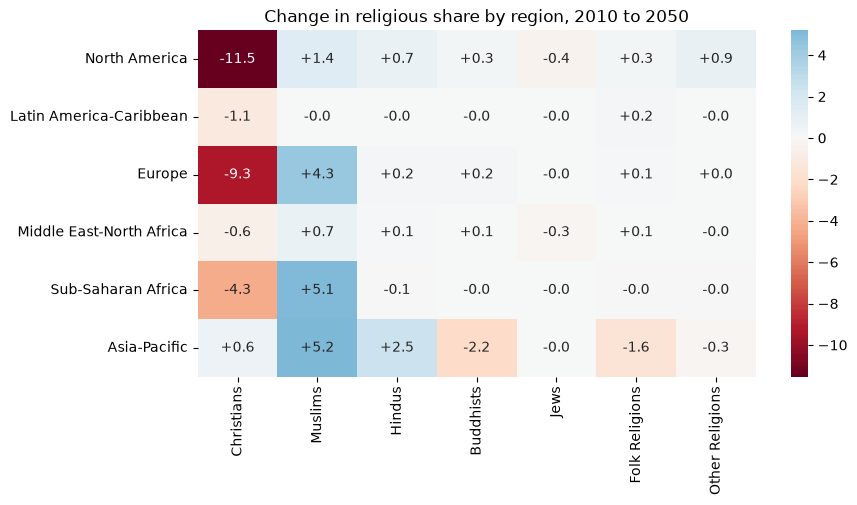

In [21]:
rel_df = pd.read_csv("rounded_population (1).csv", skipinitialspace=True)
rel_df["Region"] = rel_df["Region"].str.strip()
rel_df["Country"] = rel_df["Country"].str.strip()

df['Major_Religions_Population'] = df[['Christians', 'Muslims', 'Hindus', 'Buddhists']].sum(axis=1)

religions = ['Christians', 'Muslims', 'Hindus', 'Buddhists', 'Jews', 'Folk Religions', 'Other Religions']
df['Religious Total'] = df[religions].sum(axis=1)
df['Atheists/Agnostics %'] = df['Unaffiliated'] / df['All Religions'] * 100

rel_regions = rel_df[(rel_df.Country == "All Countries") & (rel_df.Region != "World")]

plt.figure(figsize=(9, 4.5))
sns.heatmap(share_change(rel_regions, "Region"), cmap="RdBu", center=0, annot=True, fmt="+.1f")
plt.title("Change in religious share by region, 2010 to 2050")
plt.ylabel("")
plt.show()

### Top 30 country movers
Countries with at least 1 million people, ranked by their biggest shift in any religion.

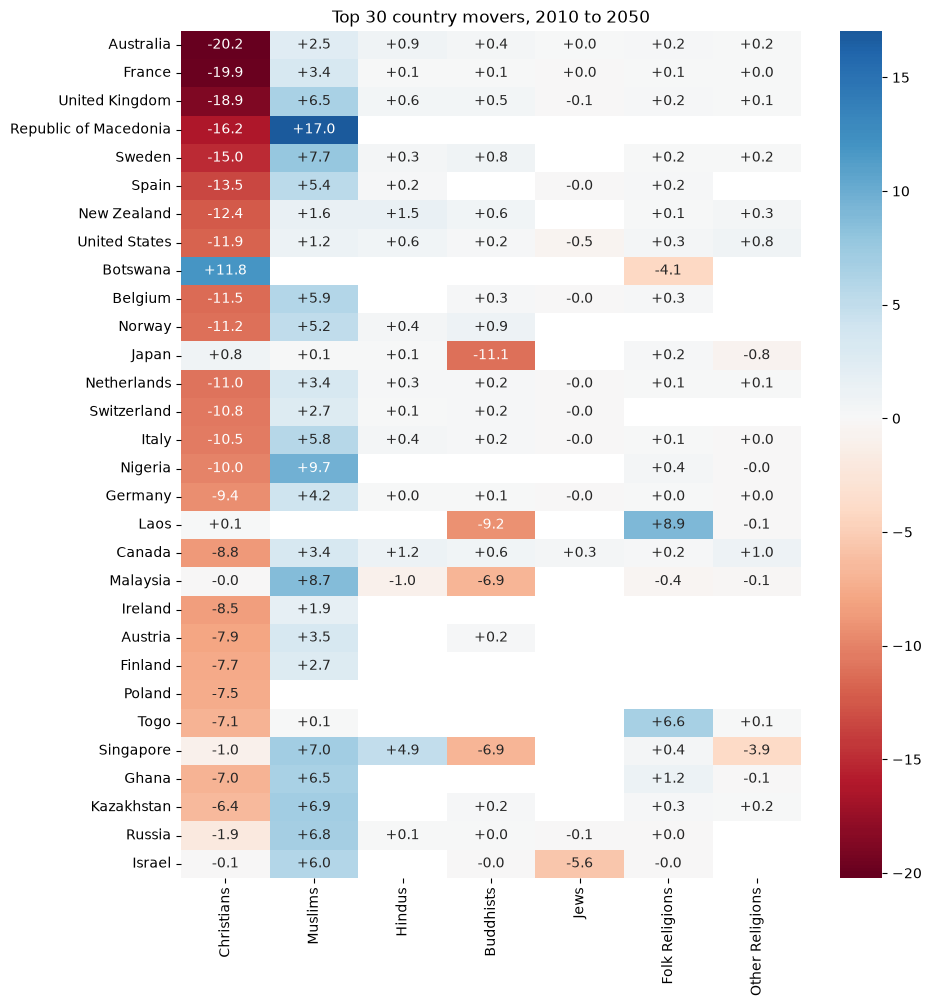

In [20]:
rel_countries = rel_df[rel_df.Country != "All Countries"]
rel_change = share_change(rel_countries, "Country")

rel_big = rel_countries[(rel_countries.Year == 2010) & (rel_countries["All Religions"] >= 1_000_000)].Country
rel_top = rel_change[rel_change.index.isin(rel_big)].abs().max(axis=1).nlargest(30).index

plt.figure(figsize=(10, 11))
sns.heatmap(rel_change.loc[rel_top], cmap="RdBu", center=0, annot=True, fmt="+.1f")
plt.title("Top 30 country movers, 2010 to 2050")
plt.ylabel("")
plt.show()

## Interactive: share over time by region
Hover for exact values, click legend items to hide or isolate a religion, drag to zoom.

In [19]:
import plotly.express as px

rel_regions = rel_df[(rel_df.Country == "All Countries") & (rel_df.Region != "World")]
rel_groups = list(rel_df.columns[3:-1])  # the 8 religion columns

long = rel_regions.melt(id_vars=["Year", "Region", "All Religions"], value_vars=rel_groups,
                        var_name="Religion", value_name="People")
long["Share (%)"] = long["People"] / long["All Religions"] * 100

fig = px.line(long, x="Year", y="Share (%)", color="Religion", facet_col="Region",
              facet_col_wrap=3, markers=True, height=650,
              title="Religious share by region, 2010 to 2050")
fig.update_xaxes(dtick=10)
fig.show()

## Interactive: world map of share change
Use the slider under the map to switch religion. Hover a country for its exact change.

In [18]:
map_df = rel_change.reset_index().melt(id_vars="Country", var_name="Religion", value_name="Change (pp)")

fig = px.choropleth(map_df, locations="Country", locationmode="country names",
                    color="Change (pp)", animation_frame="Religion",
                    color_continuous_scale="RdBu", color_continuous_midpoint=0,
                    range_color=(-20, 20), title="Change in religious share, 2010 to 2050")
fig.show()